## Imports

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sys
from pathlib import Path
from types import SimpleNamespace
import matplotlib.colors as mcolors
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
from scipy.stats import gaussian_kde
from collections import Counter

# Add the parent of mixture_density_network to sys.path
project_root = Path().absolute().parent  # points to Madidi_forest_analysis
sys.path.append(str(project_root))
print("Added to sys.path:", project_root)
from mixture_density_network.src.blocks import MixtureDensityNetwork, NoiseType
from mixture_density_network.training.train import LitModel

Added to sys.path: /stor/work/Wilke/kelly/Madidi_forest_analysis


/stor/work/Wilke/kelly/Madidi_forest_analysis/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/stor/work/Wilke/kelly/Madidi_forest_analysis/.venv/lib/python3.11/site-packages/lightning_fabric/__init__.py:36: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__("pkg_resources").declare_namespace(__name__)


## Device Configuration

In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
device

device(type='cpu')

## Load Data and Model

In [3]:
interests = ["DrySeasonDeficit", "ResinPi", "TotalP"]
dir_name = "batch32_epochs100_lr0.0004_weightdecay1e-06_beta10.9_beta20.95_dropout0.1_numcomponents5_hidden64"

# Split by underscores
parts = dir_name.split("_")
# Extract parameters
params = {}
for part in parts:
    if part.startswith("batch"):
        params["batch_size"] = int(part.replace("batch", ""))
    elif part.startswith("epochs"):
        params["epochs"] = int(part.replace("epochs", ""))
    elif part.startswith("lr"):
        params["learn_rate"] = float(part.replace("lr", ""))
    elif part.startswith("weightdecay"):
        params["weight_decay"] = float(part.replace("weightdecay", ""))
    elif part.startswith("beta1"):
        params["beta1"] = float(part.replace("beta1", ""))
    elif part.startswith("beta2"):
        params["beta2"] = float(part.replace("beta2", ""))
    elif part.startswith("dropout"):
        params["dropout"] = float(part.replace("dropout", ""))
    elif part.startswith("numcomponents"):
        params["num_components"] = int(part.replace("numcomponents", ""))
    elif part.startswith("hidden"):
        params["hidden_size"] = int(part.replace("hidden", ""))
    elif part.startswith("rarity"):
        params["rarity_threshold"] = int(part.replace("rarity", ""))
        
# Default rarity_threshold to None if not found
params["rarity_threshold"] = params.get("rarity_threshold", None)

print(params)

{'batch_size': 32, 'epochs': 100, 'learn_rate': 0.0004, 'weight_decay': 1e-06, 'beta1': 0.9, 'beta2': 0.95, 'dropout': 0.1, 'num_components': 5, 'hidden_size': 64, 'rarity_threshold': None}


In [4]:
interests_data = {}

for interest in interests:    
    # Define directories
    data_dir = Path(f"../output/Panama/{interest}/{dir_name}")
    output_dir = Path(f"figures/Panama/{interest}/{dir_name}")
    output_dir.mkdir(parents=True, exist_ok=True)

    # Pick the checkpoint with the lowest val_loss (most negative)
    checkpoint_files = list((data_dir / "checkpoints").glob("checkpoint_epoch=*_val_loss=*.ckpt"))
    best_checkpoint = min(checkpoint_files, key=lambda p: float(p.name.split("val_loss=")[-1].replace(".ckpt","")))

    # Extract best epoch 
    best_epoch = int(best_checkpoint.name.split("checkpoint_epoch=")[1].split("_")[0])
    print(f"Best epoch for {interest}: {best_epoch}")

    # Load dataset
    rarity_suffix = f"_rarity{params['rarity_threshold']}" if params["rarity_threshold"] else ""
    dataset_path = Path(f"../data/metadata/panama/dataset_{interest}{rarity_suffix}.pt")
    dataset = torch.load(dataset_path)
    X_train = dataset["train"]["embedding"].to(device)
    y_train = dataset["train"][interest].to(device)
    X_val = dataset["val"]["embedding"].to(device)
    y_val = dataset["val"][interest].to(device)
    X_test = dataset["test"]["embedding"].to(device)
    y_test = dataset["test"][interest].to(device)

    # Build train/test DataFrames 
    train_df = pd.DataFrame({
        'FEATURE_ID': dataset['train']['FEATURE_ID'],
        interest: dataset['train'][interest].cpu().numpy(),
        'embedding': list(dataset['train']['embedding'].cpu().numpy())
    })

    test_df = pd.DataFrame({
        'FEATURE_ID': dataset['test']['FEATURE_ID'],
        interest: dataset['test'][interest].cpu().numpy(),
        'embedding': list(dataset['test']['embedding'].cpu().numpy())
    })

    # Load model
    args = SimpleNamespace(
        data_file=str(dataset_path),
        lr=params["learn_rate"],
        weight_decay=params["weight_decay"],
        batch_size=params["batch_size"],
        epochs=params["epochs"],
        beta1=params["beta1"],
        beta2=params["beta2"],
        dropout=params["dropout"],
        num_components=params["num_components"],
        hidden_dim=params["hidden_size"],
    )
    model_module = LitModel.load_from_checkpoint(checkpoint_path=str(best_checkpoint), args=args, map_location=device,)
    model = model_module.model.to(device)
    model.eval()

    # Generate predictions
    with torch.no_grad():
        y_hat = model.sample(X_test)

    # Reverse normalization
    y_mean = torch.tensor(train_df[interest].values, dtype=torch.float32).mean().item()
    y_std = torch.tensor(train_df[interest].values, dtype=torch.float32).std().item()
    y_hat_unnormalized = y_hat * y_std + y_mean
    y_test_unsq = y_test.unsqueeze(1)

    # Rarity distribution
    all_splits = []
    for split in ['train', 'val', 'test']:
        df_split = pd.DataFrame({'FEATURE_ID': dataset[split]['FEATURE_ID'].numpy()})
        all_splits.append(df_split)
    all_df = pd.concat(all_splits, ignore_index=True)
    feature_counts = all_df['FEATURE_ID'].value_counts().reset_index()
    feature_counts.columns = ['FEATURE_ID', 'num_plots']
    rarity_threshold = 4
    feature_counts['rarity'] = ['Rare' if n <= rarity_threshold else 'Common' for n in feature_counts['num_plots']]

    # Store everything
    interests_data[interest] = {
        "dataset": dataset,
        "best_epoch": best_epoch,
        "train_df": train_df,
        "test_df": test_df,
        "X_test": X_test,
        "y_test": y_test_unsq,
        "y_hat": y_hat_unnormalized,
        "feature_counts": feature_counts,
        "output_dir": output_dir
    }

Best epoch for DrySeasonDeficit: 8
Best epoch for ResinPi: 2
Best epoch for TotalP: 9


In [7]:
normal_names = {
    "DrySeasonDeficit": "Dry-Season Moisture",
    "ResinPi": "Resin Phosphorus",
    "TotalP": "Total Phosphorus",
}

In [8]:
def darken_color(color, amount):
    """
    Darken the given color by multiplying (1-luminosity) by amount
    """
    c = mcolors.to_rgb(color)
    return tuple(max(min(comp * amount, 1), 0)for comp in c)

## Plot Rarity Distribution

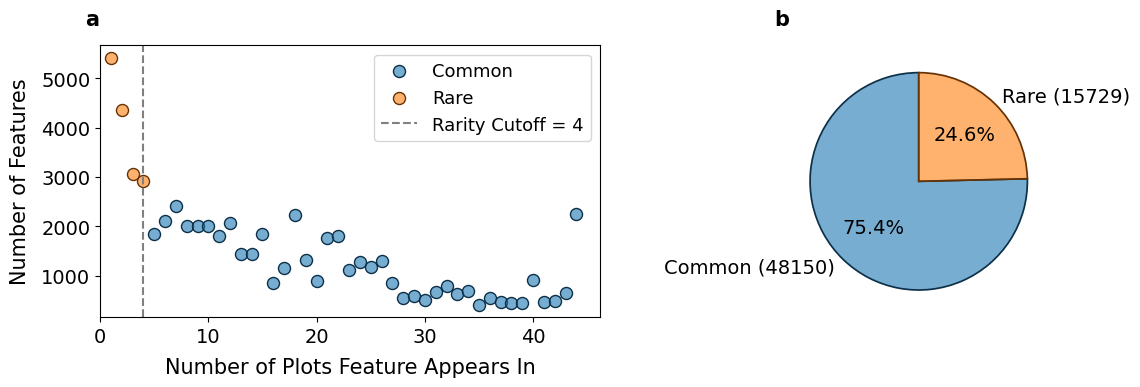

In [9]:
# Get the data for one interest (they are all the same)
interest, data = next(iter(interests_data.items()))
feature_counts = data["feature_counts"]

# Prep data for scatterplot
scatter_data = feature_counts.groupby('num_plots').size().reset_index(name='count')
scatter_data['rarity'] = scatter_data['num_plots'].apply(lambda x: 'Rare' if x <= rarity_threshold else 'Common')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = {"Rare": "tab:orange", "Common": "tab:blue"}

# Scatterplot on the left
for rarity, subset in scatter_data.groupby('rarity'):
    color = colors[rarity]
    fill = mcolors.to_rgba(color, alpha=0.6)
    edge = darken_color(color, amount=0.4)
    axes[0].scatter(
        subset['num_plots'],
        subset['count'],
        label=rarity,
        s=75,
        facecolors=fill,
        edgecolors=edge, 
        linewidths=1
    )

axes[0].axvline(rarity_threshold, color='gray', linestyle='--', label=f'Rarity Cutoff = {rarity_threshold}')
axes[0].set_xlabel('Number of Plots Feature Appears In', fontsize=15, labelpad=8)
axes[0].set_xlim(left=0)
axes[0].set_ylabel('Number of Features', fontsize=15, labelpad=8)
axes[0].tick_params(axis='both', labelsize=14)
axes[0].legend(fontsize=13, title=None)

# Pie chart on the right
rarity_counts = feature_counts['rarity'].value_counts()
wedges, texts, autotexts = axes[1].pie(
    rarity_counts,
    labels=[f"{label} ({count})" for label, count in rarity_counts.items()],
    autopct="%1.1f%%",
    startangle=90,
    colors=[colors['Common'], colors['Rare']],
    wedgeprops={'linewidth': 1.25}
)

# Apply transparency and darker edges
for w, c in zip(wedges, [colors['Common'], colors['Rare']]):
    rgba = mcolors.to_rgba(c, alpha=0.6)
    w.set_facecolor(rgba)
    w.set_edgecolor(darken_color(c, amount=0.4))

# Font sizes
for t in texts + autotexts:
    t.set_fontsize(14)

# Add letter labels
labels = ["a", "b"]
for ax, label in zip(axes, labels): 
    ax.annotate(f"{label}", xy=(-0.03, 1.06), xycoords='axes fraction', fontsize=15, fontweight='bold', va='bottom', ha='left')

plt.tight_layout()
plt.savefig("figures/Panama/final/rarity_distribution.pdf", dpi=300)
plt.show()

## Plot Loss

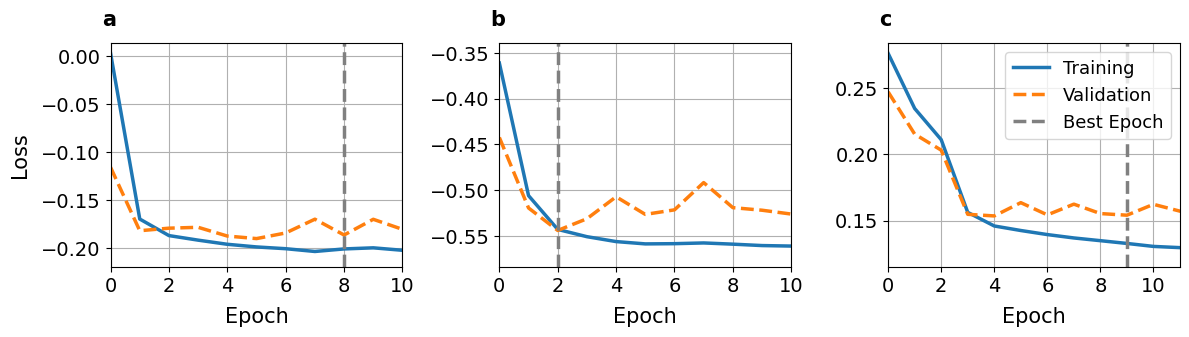

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes = axes.flatten()
labels = ['a', 'b', 'c']

for ax, (interest, data), label in zip(axes, interests_data.items(), labels):
    output_dir = data["output_dir"]
    data_dir = Path(f"../output/Panama/{interest}/{dir_name}")

    metrics_csv = data_dir / "training/version_0/metrics.csv"
    metrics = pd.read_csv(metrics_csv)

    train_losses = metrics[['epoch', 'train_loss']].dropna().sort_values('epoch')
    val_losses = metrics[['epoch', 'val_loss']].dropna().sort_values('epoch')

    epochs = train_losses['epoch'].values
    ax.plot(epochs, train_losses['train_loss'], label='Training', color='tab:blue', linewidth=2.5)
    ax.plot(epochs, val_losses['val_loss'], label='Validation', color='tab:orange', linestyle='--', linewidth=2.5)

    ax.tick_params(labelsize=14)
    ax.grid(True)

    # Add vertical line at best epoch
    ax.axvline(data["best_epoch"], color='gray', linestyle='--', label='Best Epoch', linewidth=2.5)

    # Set x-axis a bit beyond the best checkpoint epoch
    buffer = 2  # extra epochs past best
    ax.set_xlim(left=0, right=data["best_epoch"] + buffer)

    # Expand y-limits to leave space for legend
    # y_max = max(train_losses['train_loss'].max(), val_losses['val_loss'].max())
    # y_min = min(train_losses['train_loss'].min(), val_losses['val_loss'].min())
    # ax.set_ylim(y_min - 0.3, y_max + 0.6)

    ax.set_xlabel('Epoch', fontsize=15, labelpad=8)

    # Only show y-label on the first subplot
    if ax == axes[0]:
        ax.set_ylabel('Loss', fontsize=15, labelpad=8)

    # Only show legend on the last subplot
    if ax == axes[-1]:
        ax.legend(fontsize=13, loc='upper right')
 
    # Add letter labels
    ax.annotate(f"{label}", xy=(-0.03, 1.06), xycoords='axes fraction', fontsize=15, fontweight='bold', va='bottom', ha='left')

# Define consistent x-ticks starting at 0
x_min = 0
x_max = max(ax.get_xlim()[1] for ax in axes)  
x_ticks = np.arange(x_min, x_max + 1, step=2)  
for ax in axes:
    ax.set_xticks(x_ticks)

plt.tight_layout()  
plt.savefig("figures/Panama/final/combined_loss_all.pdf", dpi=300)
plt.show()

## Plot Distribution + Model's Recreation

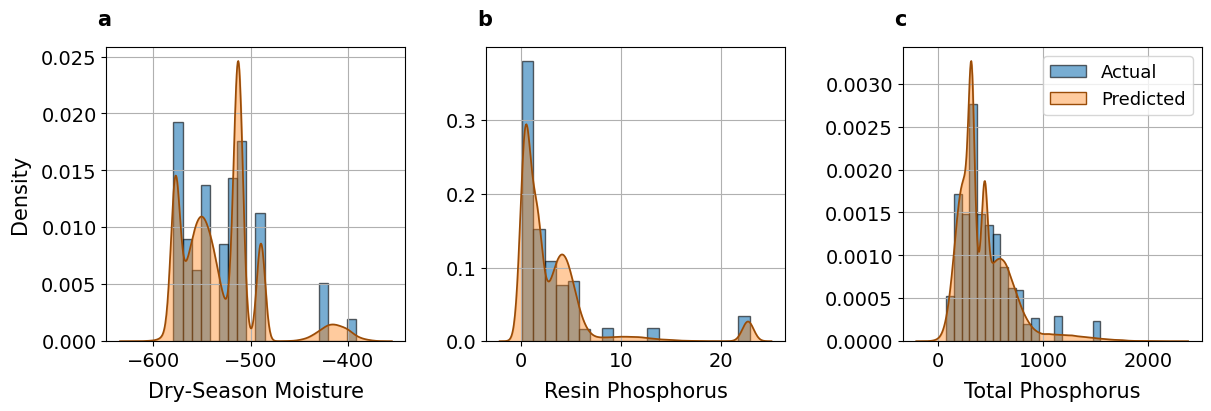

In [9]:
labels = ["a", "b", "c"]
num_interests = len(interests_data)

fig, axes = plt.subplots(
    1, num_interests,
    figsize=(12, 4),
    constrained_layout=True,
    gridspec_kw={'wspace': 0.1}
)

if num_interests == 1:
    axes = [axes]

for i, (ax, (interest, data), label) in enumerate(zip(axes, interests_data.items(), labels)):
    y_test = data["y_test"]
    y_hat = data["y_hat"]

    actual = y_test[:, 0].cpu().numpy()
    predicted = y_hat[:, 0].cpu().numpy()

    # Histogram
    ax.hist(actual, bins=20, alpha=0.6, label='Actual', density=True, color='tab:blue', edgecolor='black')

    # KDE 
    kde = gaussian_kde(predicted)
    x_margin = (predicted.max() - predicted.min()) * 0.05  # 5% margin
    x_vals = np.linspace(predicted.min() - x_margin, predicted.max() + x_margin, 500)
    kde_vals = kde(x_vals)
    ax.fill_between(x_vals, kde_vals, color=mcolors.to_rgba('tab:orange', 0.4))
    ax.plot(x_vals, kde_vals, color=darken_color('tab:orange', amount=0.6), linewidth=1.25)

    ax.set_xlabel(normal_names.get(interest, interest), fontsize=15, labelpad=8)
    ax.set_ylabel('Density', fontsize=15, labelpad=8)
    ax.tick_params(axis='both', labelsize=14)
    ax.grid(True)

    # Only show y-label on the first subplot
    if i != 0:
        ax.set_ylabel('')

    # Only show legend on the last subplot
    if i == (num_interests - 1):
        # Create KDE proxy
        kde_proxy = mpatches.Patch(facecolor=mcolors.to_rgba('tab:orange', 0.4), edgecolor=darken_color('tab:orange', amount=0.6), label='Predicted')
        handles, labels = ax.get_legend_handles_labels()
        handles.append(kde_proxy)
        ax.legend(handles=handles, fontsize=13, loc='upper right')

    # Add letter labels
    ax.annotate(f"{label}", xy=(-0.03, 1.06), xycoords='axes fraction', fontsize=15, fontweight='bold', va='bottom', ha='left')

plt.savefig("figures/Panama/final/combined_distribution_all.pdf", dpi=300)
plt.show()

## Plot Model Predictions

In [11]:
def generate_predictions(embedding, num_samples):
    """Generate predicted samples of the target variable for a given embedding."""
    
    embedding_tensor = torch.tensor(embedding, dtype=torch.float32).unsqueeze(0).repeat(num_samples, 1).to(device)
    with torch.no_grad():
        predictions = model.sample(embedding_tensor).cpu().numpy()
    return pd.DataFrame(predictions, columns=[interest])

In [12]:
# Plotting for each feature
def plot_feature_actual_vs_predicted(test_df, train_df, feature_id, num_samples, ax, shared_bins, xmin, xmax, ymax):
    """Plot actual values as vertical lines with horizontal jitter for duplicates,
    and KDE of predictions for a single FEATURE_ID."""
    
    # Filter df_combined to only include rows of the specified FEATURE_ID
    feature_data = test_df[test_df['FEATURE_ID'] == feature_id]
    
    # Extract the actual values of the interest variable and the embedding
    actual_values = feature_data[interest].values
    embedding = feature_data['embedding'].iloc[0]

    # Generate predictions
    predictions = generate_predictions(embedding, num_samples)

    # Unnormalize predictions
    y_mean = torch.tensor(train_df[interest].values, dtype=torch.float32).mean().item()
    y_std = torch.tensor(train_df[interest].values, dtype=torch.float32).std().item()
    predictions[interest] = predictions[interest] * y_std + y_mean
    pred_vals = predictions[interest].values

    # Plot KDE of predicted values with shared x-axis if provided
    if xmin is None:                                              
        x_vals = np.linspace(pred_vals.min(), pred_vals.max(), 500)
    else:
        x_vals = np.linspace(xmin, xmax, 500)

    kde = gaussian_kde(pred_vals)
    kde_vals = kde(x_vals)

    ax.fill_between(x_vals, kde_vals, color='tab:orange', alpha=0.4, zorder=2)
    ax.plot(x_vals, kde_vals, color=darken_color('tab:orange', amount=0.5), linewidth=1, zorder=2)

    # If there is only one actual value, plot vertical line
    if len(actual_values) == 1 or np.allclose(actual_values, actual_values[0]):
        # Rug for actual values
        jitter = (np.random.rand(len(actual_values)) - 0.5) * 0.01
        sns.rugplot(actual_values + jitter, ax=ax, color='tab:blue', linewidth=2.5, height=1, zorder=1)

    else:
        # Plot histogram of actual values with shared bins if provided
        if shared_bins is not None:                  
            bins = shared_bins
        else:
            data_min, data_max = actual_values.min(), actual_values.max()
            data_range = data_max - data_min
            binwidth = data_range / 15 if data_range > 0 else 1
            bins = np.arange(data_min, data_max + binwidth, binwidth)

        ax.hist(actual_values, bins=bins, color='tab:blue', alpha=0.6, label='Actual', density=True, edgecolor='black')

    # Apply shared axis limits for the row
    if xmin is not None:                           
        ax.set_xlim(xmin, xmax)
    if ymax is not None:
        ax.set_ylim(0, ymax)

    # Labels, title, and styling
    ax.set_xlabel(normal_names.get(interest, interest), fontsize=15, labelpad=8)
    ax.set_ylabel('Density', fontsize=15, labelpad=8)
    ax.set_title(f'Feature ID {feature_id}', fontsize=14)
    ax.tick_params(axis='both', labelsize=14)
    ax.grid(True)

    # Only show legend in the top right plot
    if ax.get_subplotspec().rowspan.start == 0 and ax.get_subplotspec().colspan.start == 2:
        kde_proxy = mpatches.Patch(facecolor=mcolors.to_rgba('tab:orange', 0.4), edgecolor=darken_color('tab:orange', amount=0.6), label='Predicted')
        handles, labels = ax.get_legend_handles_labels()
        handles.append(kde_proxy)
        ax.legend(handles=handles, fontsize=13, loc='upper right')

Feature usage counts:
  36625: 31 times
  91882: 12 times
  16916: 40 times
  19845: 20 times
  89159: 24 times
  56274: 25 times
  7385: 24 times
  37419: 33 times
  64543: 28 times


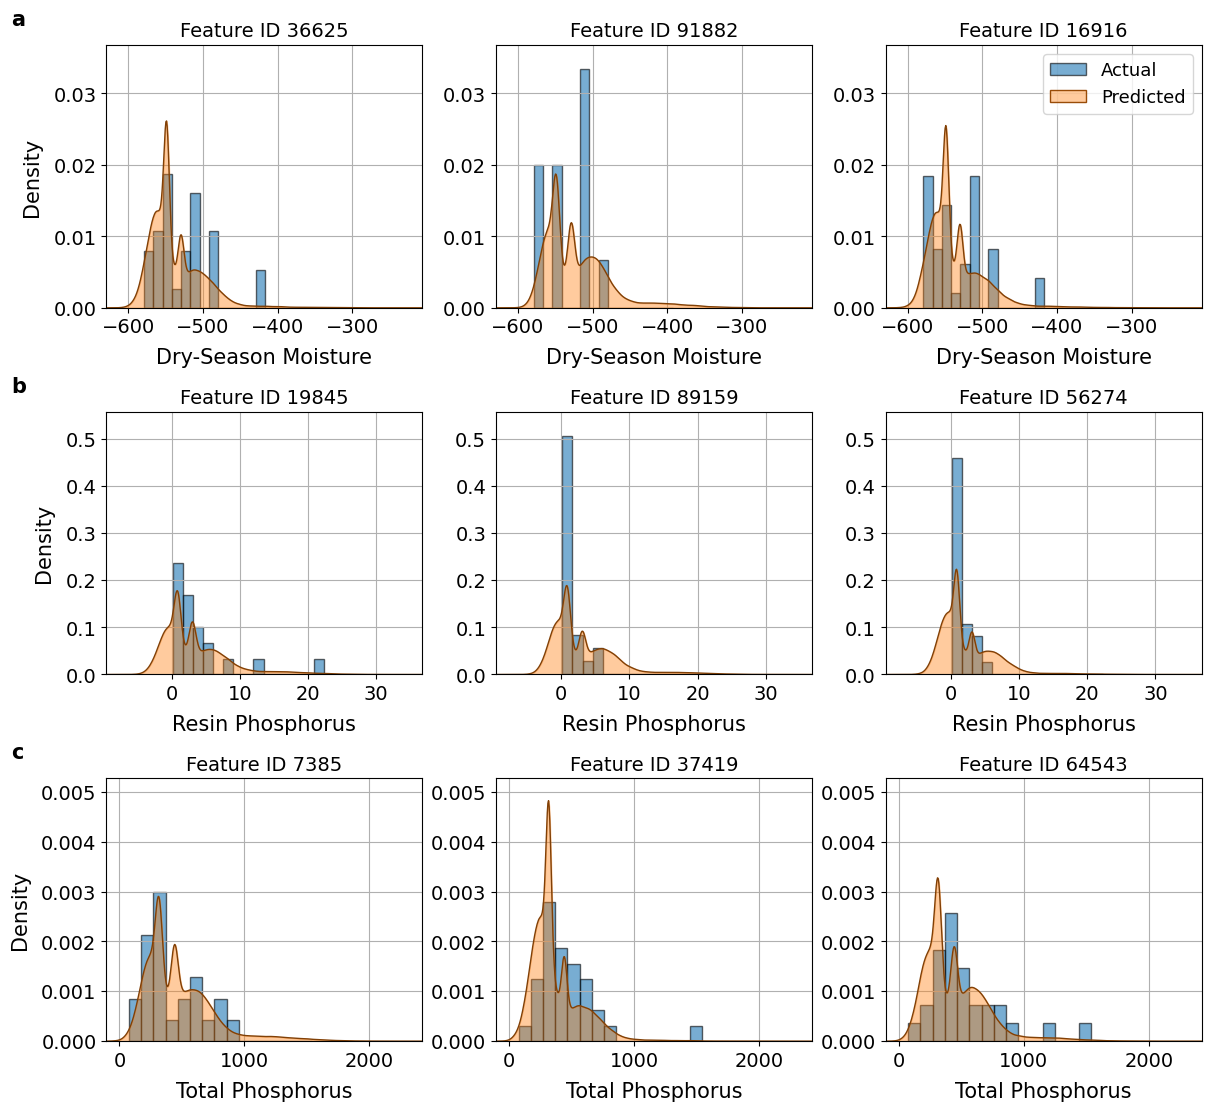

In [18]:
feature_counts = Counter()

num_features_per_interest = 3  # 3 random features per interest
interests = list(interests_data.keys())
num_interests = len(interests)

fig, axes = plt.subplots(num_interests, num_features_per_interest, figsize=(12, 11), constrained_layout=True)

for row, interest in enumerate(interests):
    # Choose features
    data = interests_data[interest]
    test_df = data["test_df"]
    train_df = data["train_df"]
    random_features = test_df['FEATURE_ID'].sample(3).unique()

    ##### Step 1: Data Collection and Initial Range Finding
    # Must collect data twice: once for ranges, and once for plotting, but can collect actual/pred values and store them for the second pass
    
    # Storage for individual feature data for the second pass
    feature_data_for_plot = {} 
    
    all_actual = [] # For shared x/bin range calculation
    all_pred = []   # For shared x/bin range calculation
    
    y_mean = train_df[interest].mean()
    y_std = train_df[interest].std()

    for feature_id in random_features:
        fdata = test_df[test_df['FEATURE_ID'] == feature_id]

        # Count the number of plots this feature appears in
        count = len(fdata)
        feature_counts[feature_id] += count

        # Collect actual
        actual_vals = fdata[interest].values
        all_actual.append(actual_vals)

        # Collect predicted
        embedding = fdata['embedding'].iloc[0]
        preds = generate_predictions(embedding, num_samples=100000)

        # Unnormalize
        preds_unnorm = preds[interest] * y_std + y_mean
        pred_vals = preds_unnorm.values
        all_pred.append(pred_vals)
        
        # Store for the second pass
        feature_data_for_plot[feature_id] = {
            'actual_vals': actual_vals,
            'pred_vals': pred_vals,
            'embedding': embedding
        }

    # Flatten lists for shared ranges
    all_actual_flat = np.concatenate(all_actual)
    all_pred_flat = np.concatenate(all_pred)

    ##### Step 2: Compute Shared X Range and Bins
    
    # Compute shared bins
    data_min, data_max = all_actual_flat.min(), all_actual_flat.max()
    data_range = data_max - data_min
    if data_range == 0:
        data_range = 1
    binwidth = data_range / 15
    shared_bins = np.arange(data_min, data_max + binwidth, binwidth)

    # Shared x range
    row_xmin = min(all_actual_flat.min(), all_pred_flat.min())
    row_xmax = max(all_actual_flat.max(), all_pred_flat.max())

    ##### Compute Shared Y Range
    
    # Calculate max peak across all individual feature plots
    all_peaks = [] 

    for feature_id in random_features:
        data_point = feature_data_for_plot[feature_id]
        actual_vals = data_point['actual_vals']
        pred_vals = data_point['pred_vals']

        # Individual Actual Histogram Peak
        # Only check peak if plotting histogram (not a rugplot/single line)
        if len(actual_vals) > 1 and not np.allclose(actual_vals, actual_vals[0]):
            hist_counts, _ = np.histogram(actual_vals, bins=shared_bins, density=True)
            all_peaks.append(hist_counts.max())

        # Individual Predicted KDE Peak
        kde = gaussian_kde(pred_vals)
        kde_vals = kde(np.linspace(row_xmin, row_xmax, 500))
        all_peaks.append(kde_vals.max())

    # Set shared max Y limit based on maximum individual peak
    if all_peaks:
        row_ymax = max(all_peaks) * 1.1 # Apply buffer for padding
    else:
        row_ymax = 1.0 # Fallback 

    ##### Create Subplots
    for col, feature_id in enumerate(random_features):
        ax = axes[row, col]
        plot_feature_actual_vs_predicted(test_df, train_df, feature_id, num_samples=100000, ax=ax, shared_bins=shared_bins, xmin=row_xmin, xmax=row_xmax, ymax=row_ymax)

        # Only show y-label on first column
        if col != 0:    
            ax.set_ylabel('')

# Add row letters (a, b, c) on the left of each row
row_letters = ["a", "b", "c"]
for row, letter in enumerate(row_letters):
    ax = axes[row, 0]  # first column
    ax.annotate(f"{letter}", xy=(-0.3, 1.06), xycoords='axes fraction', fontsize=15, fontweight='bold', va='bottom', ha='left')

print("Feature usage counts:")
for fid, count in feature_counts.items():
    print(f"  {fid}: {count} times")

plt.savefig(f"figures/Panama/final/actual_vs_predicted_3x3_random_all.pdf", dpi=300)
plt.show()


Feature usage counts:
 84901: 18 times
 57194: 18 times
 83730: 44 times
 15367: 35 times
 73861: 22 times
 97144: 44 times
 56266: 20 times
 83234: 33 times
 34322: 44 times


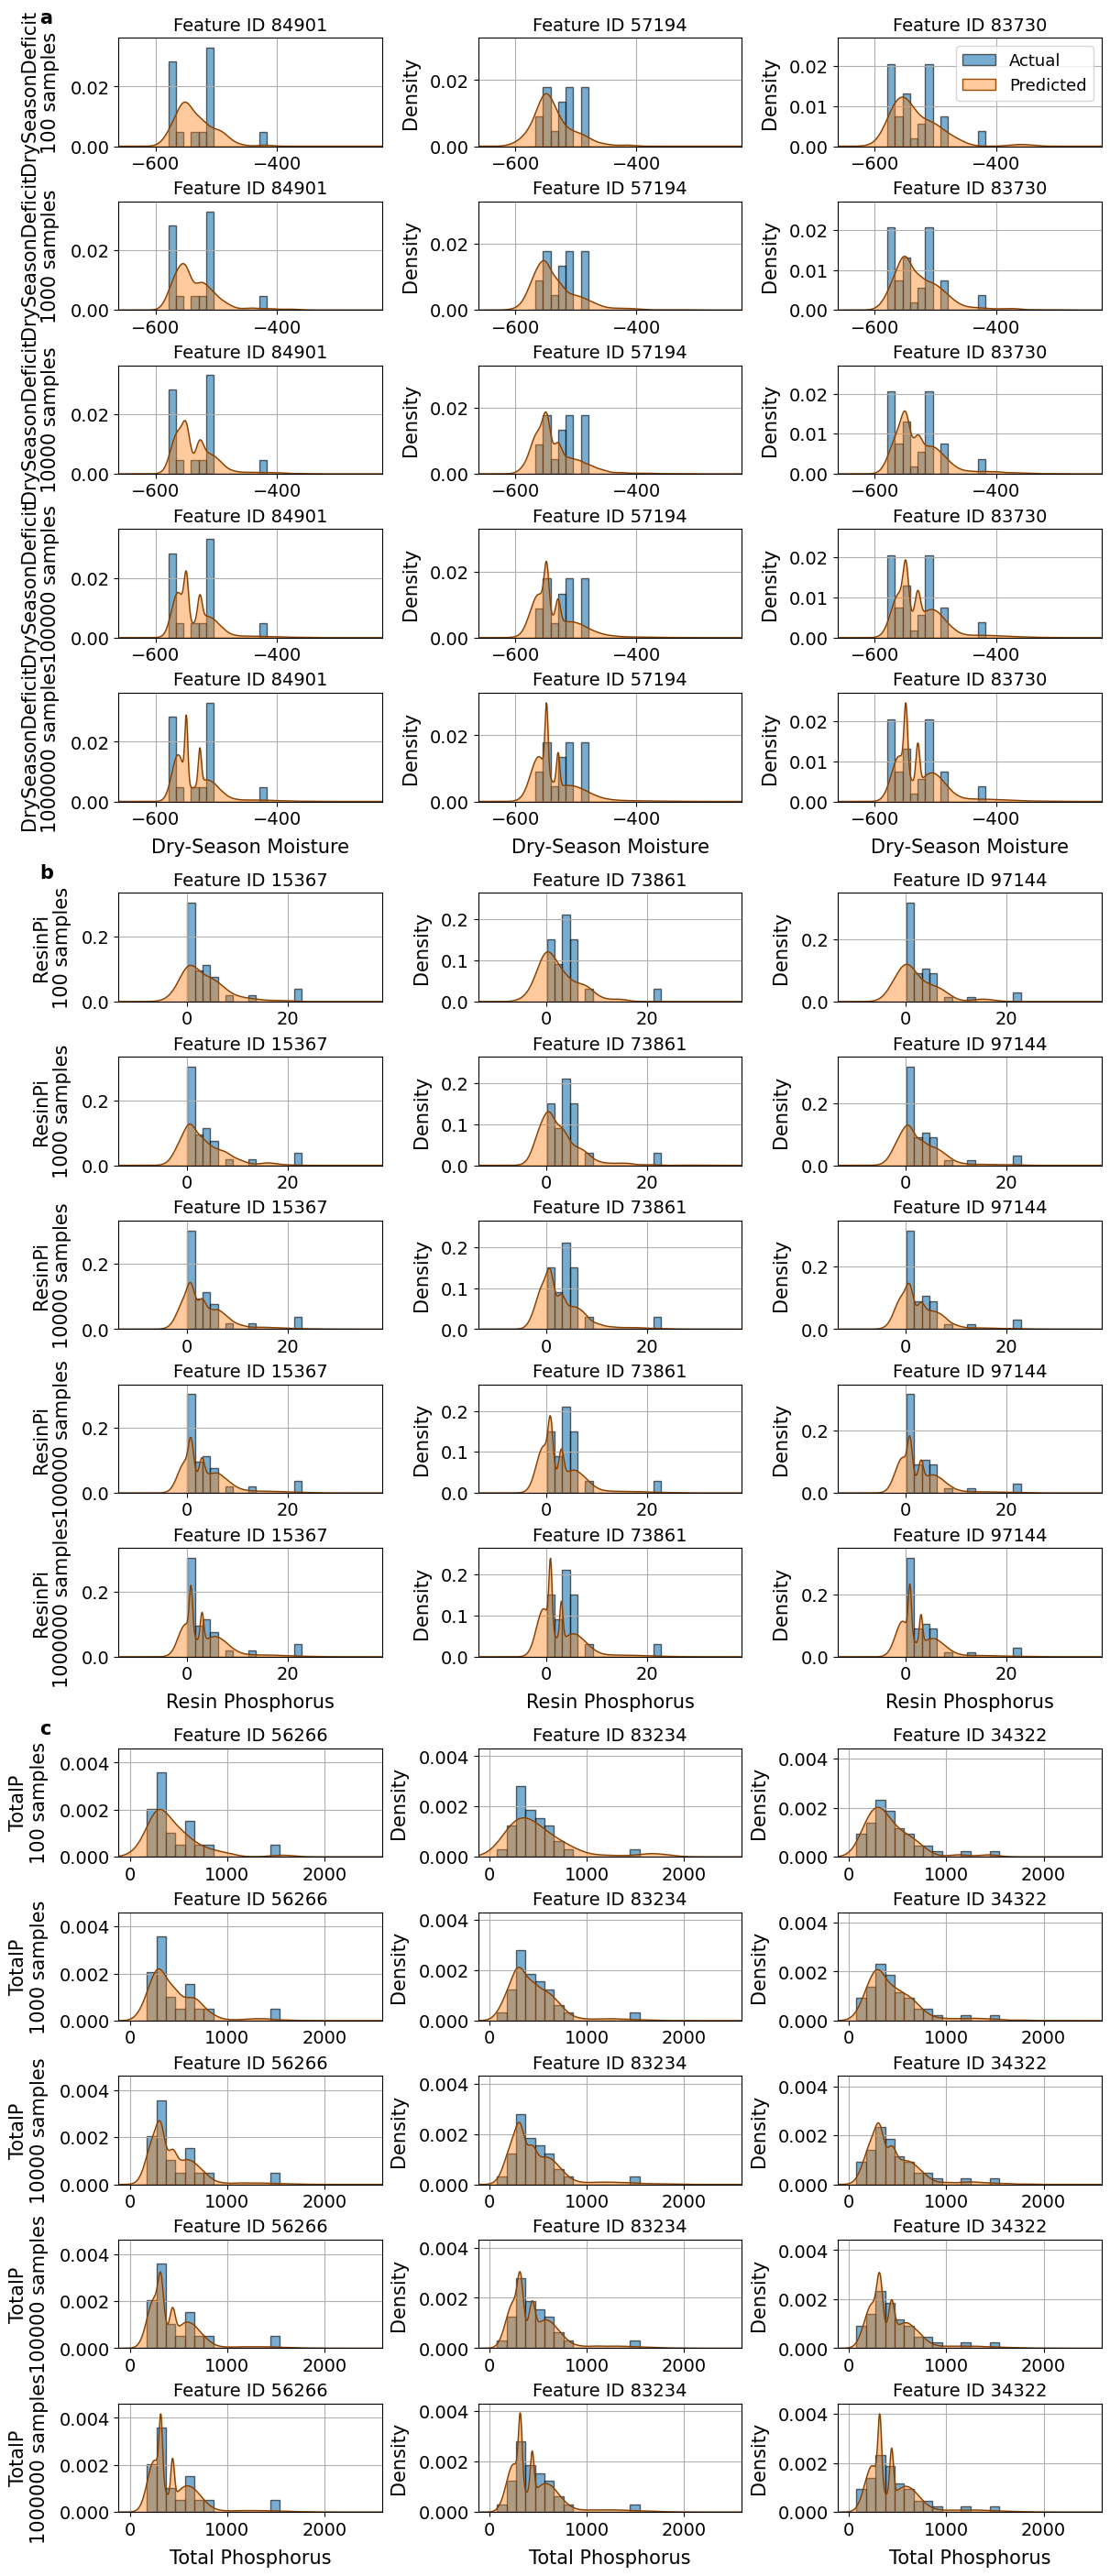

In [ ]:
# feature_counts = Counter()

# num_features_per_interest = 3
# num_samples_list = [100, 1000, 10000, 100000, 1000000]

# interests = list(interests_data.keys())
# num_interests = len(interests)

# # NEW: 3 stacked plots per feature
# fig, axes = plt.subplots(
#     num_interests * len(num_samples_list),
#     num_features_per_interest,
#     figsize=(12, 28),
#     constrained_layout=True
# )

# # Helper: index into big axes grid
# def get_ax(interest_row, sample_idx, feature_col):
#     row = interest_row * len(num_samples_list) + sample_idx
#     return axes[row, feature_col]

# # Loop over interests
# for interest_row, interest in enumerate(interests):

#     data = interests_data[interest]
#     test_df = data["test_df"]
#     train_df = data["train_df"]

#     # Fix chosen features ONCE so comparisons match
#     random_features = test_df["FEATURE_ID"].sample(num_features_per_interest).unique()

#     # Precompute normalization factors
#     y_mean = train_df[interest].mean()
#     y_std = train_df[interest].std()

#     # --- For each interest, compute shared X-range across all features AND all sample sizes ---
#     all_actual = []
#     all_pred_all_sizes = []

#     # First pass: gather actual and pred for X-range
#     for feature_id in random_features:
#         fdata = test_df[test_df["FEATURE_ID"] == feature_id]

#         actual_vals = fdata[interest].values
#         all_actual.append(actual_vals)

#         embedding = fdata["embedding"].iloc[0]

#         # Collect predictions for all three sample sizes to fix shared x-range
#         pred_vals_all = []
#         for num_samples in num_samples_list:
#             preds = generate_predictions(embedding, num_samples=num_samples)
#             preds_vals = preds[interest] * y_std + y_mean
#             pred_vals_all.append(preds_vals.values)

#         all_pred_all_sizes.extend(pred_vals_all)

#     # Flatten
#     all_actual_flat = np.concatenate(all_actual)
#     all_pred_flat = np.concatenate(all_pred_all_sizes)

#     row_xmin = min(all_actual_flat.min(), all_pred_flat.min())
#     row_xmax = max(all_actual_flat.max(), all_pred_flat.max())

#     # Determine bins for this interest
#     data_min = all_actual_flat.min()
#     data_max = all_actual_flat.max()
#     data_range = data_max - data_min if data_max > data_min else 1
#     binwidth = data_range / 15
#     shared_bins = np.arange(data_min, data_max + binwidth, binwidth)

#     # === Second pass: plot for each feature and each num_samples ===
#     for feature_col, feature_id in enumerate(random_features):

#         fdata = test_df[test_df["FEATURE_ID"] == feature_id]
#         actual_vals = fdata[interest].values
#         embedding = fdata["embedding"].iloc[0]

#         # Count feature usage
#         feature_counts[feature_id] += len(fdata)

#         # Compute shared Y limit across the 3 sample sizes
#         peaks = []

#         # Actual histogram peak
#         if len(actual_vals) > 1 and not np.allclose(actual_vals, actual_vals[0]):
#             hist_counts, _ = np.histogram(actual_vals, bins=shared_bins, density=True)
#             peaks.append(hist_counts.max())

#         # Predicted KDE peaks for each sample size
#         for num_samples in num_samples_list:
#             preds = generate_predictions(embedding, num_samples=num_samples)
#             preds_vals = preds[interest] * y_std + y_mean
#             pred_vals = preds_vals.values

#             kde = gaussian_kde(pred_vals)
#             kde_vals = kde(np.linspace(row_xmin, row_xmax, 500))
#             peaks.append(kde_vals.max())

#         row_ymax = max(peaks) * 1.1

#         # Now plot three stacked panels
#         for sample_idx, num_samples in enumerate(num_samples_list):

#             ax = get_ax(interest_row, sample_idx, feature_col)

#             plot_feature_actual_vs_predicted(
#                 test_df=test_df,
#                 train_df=train_df,
#                 feature_id=feature_id,
#                 num_samples=num_samples,
#                 ax=ax,
#                 shared_bins=shared_bins,
#                 xmin=row_xmin,
#                 xmax=row_xmax,
#                 ymax=row_ymax
#             )

#             # Label left-side panels
#             if feature_col == 0:
#                 ax.set_ylabel(f"{interest}\n{num_samples} samples")

#             # Clean x labels except bottom panel
#             if sample_idx != len(num_samples_list) - 1:
#                 ax.set_xlabel("")

# # Add row letters for interests only (top panel of each interest block)
# row_letters = ["a", "b", "c"]
# for i, letter in enumerate(row_letters):
#     ax = axes[i * len(num_samples_list), 0]
#     ax.annotate(
#         f"{letter}",
#         xy=(-0.3, 1.1),
#         xycoords="axes fraction",
#         fontsize=15,
#         fontweight="bold",
#         va="bottom",
#         ha="left"
#     )

# # plt.savefig("figures/Panama/final/actual_vs_predicted_sample_comparison.pdf", dpi=300)
# plt.show()

## Make predictions about molecules outside of the dataset 
(From: https://www.sciencedirect.com/science/article/pii/S2666389923002490?via%3Dihub)